<a href="https://colab.research.google.com/github/MarcelAzis/Student-Drop-out-Prediction/blob/main/Tugas_Kecil_PROYEK_AI_SDG4_KELOMPOK_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PROYEK AI KELOMPOK 4 — Early Warning System Risiko Dropout

**Tujuan:** memprediksi status akademik mahasiswa: **Dropout / Enrolled / Graduate**, lalu mengurutkan mahasiswa berdasarkan skor risiko Dropout.

**Dataset:** [Predict Students' Dropout and Academic Success (UCI ID 697)](https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success), 4.424 data mahasiswa, 36 fitur awal + 1 target. Datasetnya dari konteks pendidikan tinggi Portugal bukan dari Indonesia.

**Fitur:** jumlah mata kuliah diambil, jumlah lulus, nilai semester pertama, status pembayaran, beasiswa, nilai masuk, usia masuk.

**Algoritma:** Decision Tree dan Random Forest.

##Pengumpulan Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

print("Upload dulu file CSV dataset mahasiswa.")
uploaded = files.upload()
nama_file = next(iter(uploaded))

# sep=None: pandas mendeteksi pemisah koma atau titik koma
df = pd.read_csv(nama_file, sep=None, engine="python", encoding="utf-8-sig")
df.columns = df.columns.str.strip()

print("Jumlah baris dan kolom:", df.shape)
display(df.head())

Upload dulu file CSV dataset mahasiswa.


Saving Predict Students Dropout and Academic Success (1).csv to Predict Students Dropout and Academic Success (1).csv
Jumlah baris dan kolom: (4424, 37)


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


##Cleaning Data dan Preprocessing Dasar
Mengecek data kosong, baris dobel, tipe kolom, dan pastikan target isinya tiga kelas.

In [ ]:
print("Jumlah baris:", len(df))
print("Jumlah kolom:", len(df.columns))
print("Jumlah nilai kosong:", df.isna().sum().sum())
print("Jumlah baris dobel:", df.duplicated().sum())

# Hilangkan spasi berlebih pada label target
df["Target"] = df["Target"].astype(str).str.strip()
print("\nJumlah tiap kategori:")
print(df["Target"].value_counts())
print("\nTipe data:")
print(df.dtypes.head(10))

Jumlah baris: 4424
Jumlah kolom: 37
Jumlah nilai kosong: 0
Jumlah baris dobel: 0

Jumlah tiap kategori:
Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64

Tipe data:
Marital status                      int64
Application mode                    int64
Application order                   int64
Course                              int64
Daytime/evening attendance          int64
Previous qualification              int64
Previous qualification (grade)    float64
Nacionality                         int64
Mother's qualification              int64
Father's qualification              int64
dtype: object


### EDA 1: Distribusi tiga kelas (ketidakseimbangan kelas)

          Jumlah  Persentase (%)
Target                          
Dropout     1421           32.12
Enrolled     794           17.95
Graduate    2209           49.93


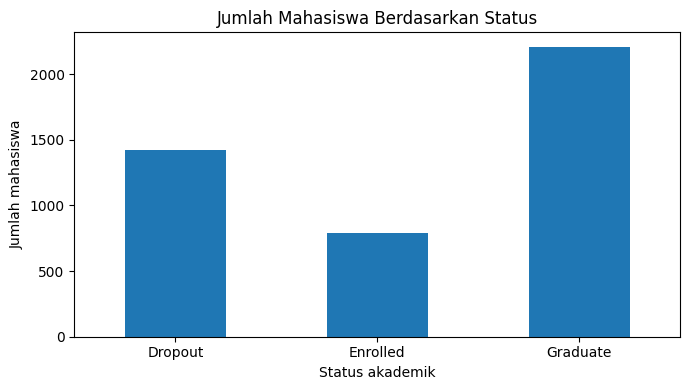

In [ ]:
urutan = ["Dropout", "Enrolled", "Graduate"]
jumlah = df["Target"].value_counts().reindex(urutan, fill_value=0)

print(pd.DataFrame({
    "Jumlah": jumlah,
    "Persentase (%)": (jumlah / jumlah.sum() * 100).round(2)
}))

jumlah.plot(kind="bar", rot=0, figsize=(7, 4))
plt.title("Jumlah Mahasiswa Berdasarkan Status")
plt.xlabel("Status akademik")
plt.ylabel("Jumlah mahasiswa")
plt.tight_layout()
plt.show()

### EDA 2: Jumlah mata kuliah diambil dan lulus (semester 1)

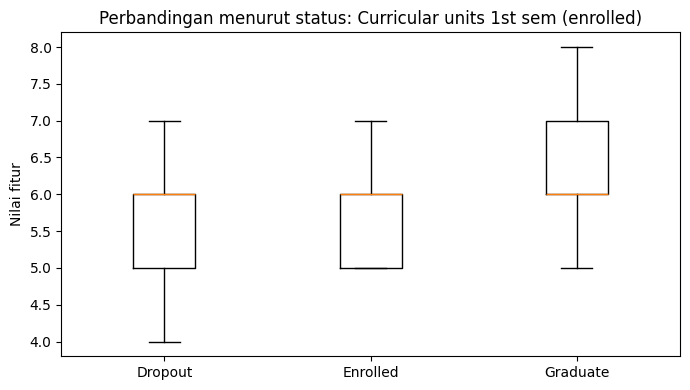

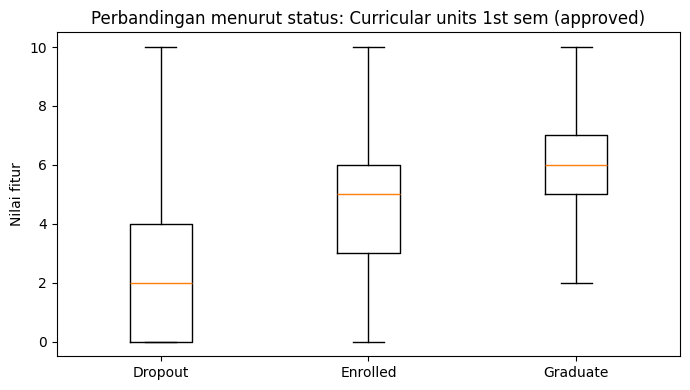

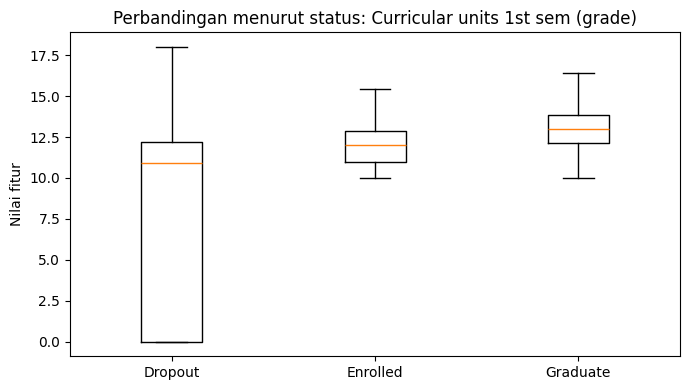

Rata-rata fitur akademik per status:


,Curricular units 1st sem (enrolled),Curricular units 1st sem (approved),Curricular units 1st sem (grade)
Target,,,
Dropout,5.82,2.55,7.26
Enrolled,5.96,4.32,11.13
Graduate,6.67,6.23,12.64


In [ ]:
kolom_akademik = [
    "Curricular units 1st sem (enrolled)",
    "Curricular units 1st sem (approved)",
    "Curricular units 1st sem (grade)"
]

for kolom in kolom_akademik:
    kelompok = [df.loc[df["Target"] == label, kolom].dropna() for label in urutan]
    plt.figure(figsize=(7, 4))
    plt.boxplot(kelompok, tick_labels=urutan, showfliers=False)
    plt.title("Perbandingan menurut status: " + kolom)
    plt.ylabel("Nilai fitur")
    plt.tight_layout()
    plt.show()

print("Rata-rata fitur akademik per status:")
display(df.groupby("Target")[kolom_akademik].mean().round(2))

### EDA 3: Status pembayaran dan persentase Dropout

Persentase status akademik menurut pembayaran (%):


Target,Dropout,Enrolled,Graduate
Tuition fees up to date,,,
0,86.55,7.95,5.49
1,24.74,19.30,55.95


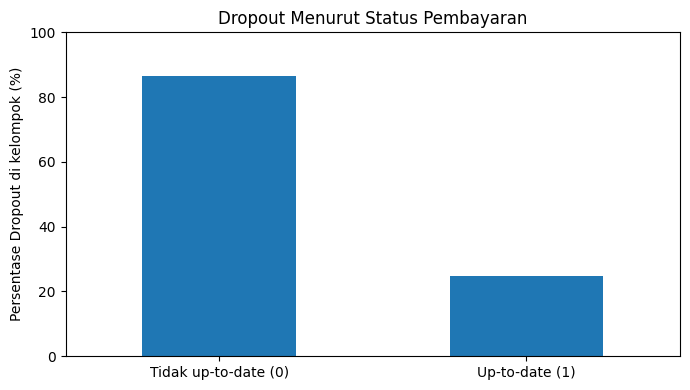

In [ ]:
tabel_bayar = pd.crosstab(
    df["Tuition fees up to date"], df["Target"], normalize="index"
) * 100
print("Persentase status akademik menurut pembayaran (%):")
display(tabel_bayar.round(2))

persen_dropout = tabel_bayar["Dropout"].reindex([0, 1])
persen_dropout.index = ["Tidak up-to-date (0)", "Up-to-date (1)"]
persen_dropout.plot(kind="bar", rot=0, figsize=(7, 4))
plt.ylabel("Persentase Dropout di kelompok (%)")
plt.title("Dropout Menurut Status Pembayaran")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

### EDA 4: Beasiswa dan status akademik

Persentase status akademik menurut beasiswa (%):


Target,Dropout,Enrolled,Graduate
Scholarship holder,,,
0,38.71,19.97,41.32
1,12.19,11.83,75.98


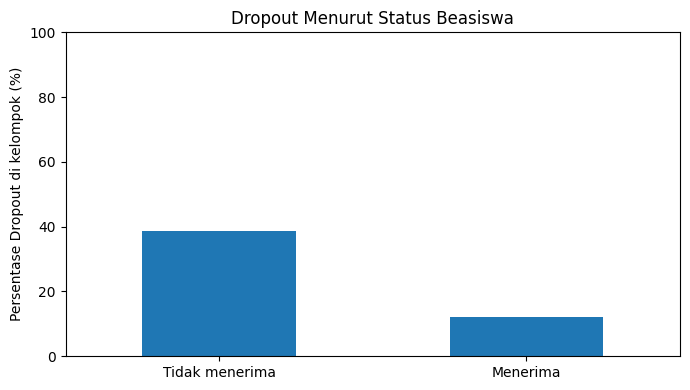

In [ ]:
tabel_beasiswa = pd.crosstab(
    df["Scholarship holder"], df["Target"], normalize="index"
) * 100
print("Persentase status akademik menurut beasiswa (%):")
display(tabel_beasiswa.round(2))

persen_dropout_beasiswa = tabel_beasiswa["Dropout"].reindex([0, 1])
persen_dropout_beasiswa.index = ["Tidak menerima", "Menerima"]
persen_dropout_beasiswa.plot(kind="bar", rot=0, figsize=(7, 4))
plt.ylabel("Persentase Dropout di kelompok (%)")
plt.title("Dropout Menurut Status Beasiswa")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

##Feature Selection

**Pemilihan manual berbasis relevansi dan waktu prediksi**, bukan klaim kalau 7 fitur otomatis adalah yang paling berpengaruh.

Semua fitur semester dua tidak digunakan karena kita merancang prediksi berdasarkan informasi setelah semester pertama.

In [ ]:
fitur = [
    "Curricular units 1st sem (enrolled)",
    "Curricular units 1st sem (approved)",
    "Curricular units 1st sem (grade)",
    "Tuition fees up to date",
    "Scholarship holder",
    "Admission grade",
    "Age at enrollment"
]

# Pilih hanya 7 fitur dan 1 target
data = df[fitur + ["Target"]].copy()

# Pastikan input berupa angka, data bermasalah jadi NaN
for kolom in fitur:
    data[kolom] = pd.to_numeric(data[kolom], errors="coerce")

print("Nilai kosong dalam 7 fitur:", data[fitur].isna().sum().sum())

# Dataset UCI asli lengkap jadi kode ini tetap aman kalau file ada nilai kosong
sebelum = len(data)
data = data.dropna(subset=fitur + ["Target"]).copy()
print("Baris terbuang karena data tidak lengkap:", sebelum - len(data))

X = data[fitur]
y = data["Target"]

print("Bentuk X (fitur):", X.shape)
print("Bentuk y (target):", y.shape)
display(X.head())
print("Label:", y.unique())

Nilai kosong dalam 7 fitur: 0
Baris terbuang karena data tidak lengkap: 0
Bentuk X (fitur): (4424, 7)
Bentuk y (target): (4424,)


,Curricular units 1st sem (enrolled),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Tuition fees up to date,Scholarship holder,Admission grade,Age at enrollment
0,0,0,0.000000,1,0,127.3,20
1,6,6,14.000000,0,0,142.5,19
2,6,0,0.000000,0,0,124.8,19
3,6,6,13.428571,1,0,119.6,20
4,6,5,12.333333,1,0,141.5,45


Label: ['Dropout' 'Graduate' 'Enrolled']


### EDA 5: Heatmap Korelasi Antar Fitur

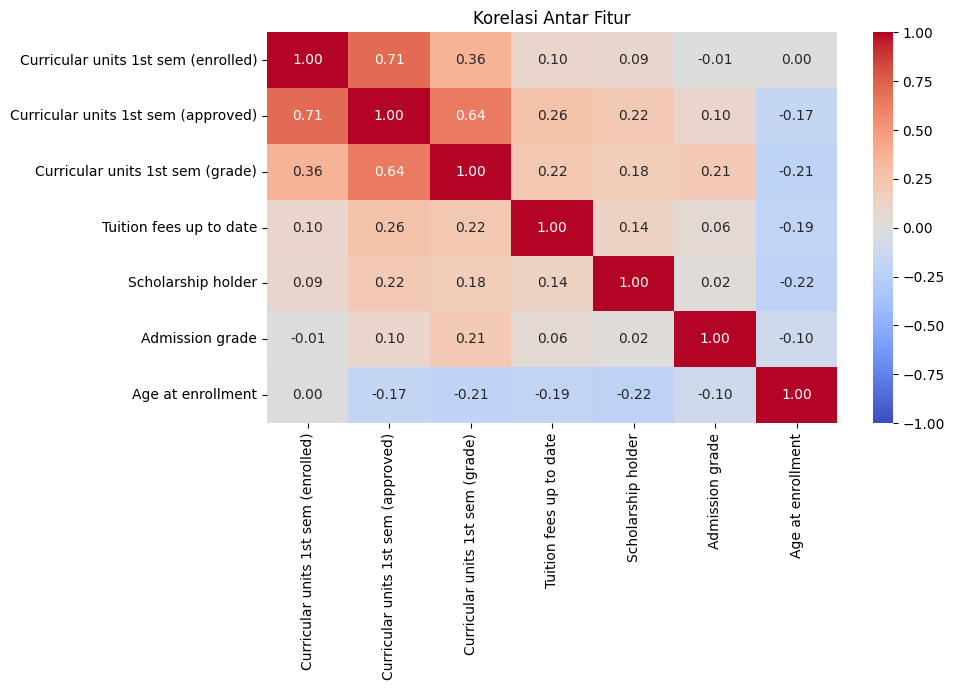

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Menghitung korelasi antar 7 fitur
korelasi = X.corr(method="spearman")

plt.figure(figsize=(10, 7))

sns.heatmap(
    korelasi,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    fmt=".2f"
)

plt.title("Korelasi Antar Fitur")
plt.tight_layout()
plt.show()

### EDA 6: Korelasi Fitur dengan Indikator Dropout

,Korelasi dengan Dropout
Curricular units 1st sem (approved),-0.522881
Curricular units 1st sem (grade),-0.442633
Tuition fees up to date,-0.429149
Scholarship holder,-0.245354
Curricular units 1st sem (enrolled),-0.180101
Admission grade,-0.098572
Age at enrollment,0.280036


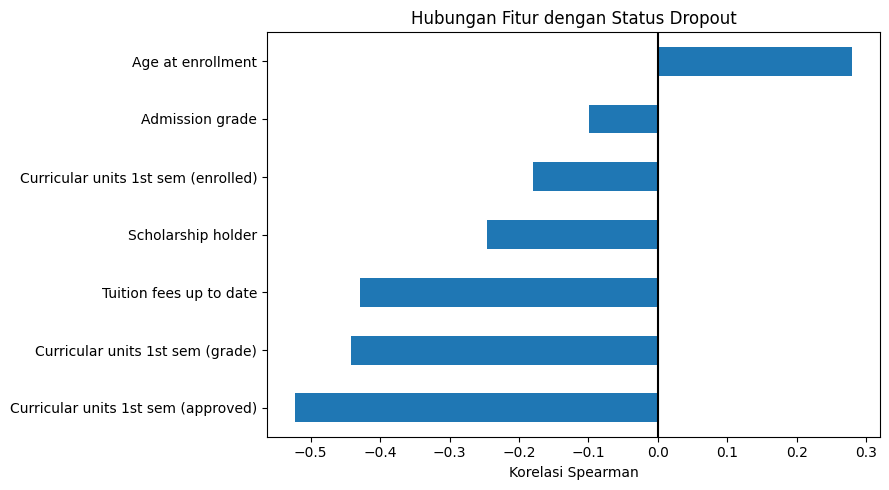

In [ ]:
# Buat indikator khusus untuk analisis EDA
data_eda = data.copy()

data_eda["Indikator_Dropout"] = (
    data_eda["Target"] == "Dropout"
).astype(int)

# Korelasi Spearman terhadap indikator Dropout
korelasi_dropout = (
    data_eda[fitur + ["Indikator_Dropout"]]
    .corr(method="spearman")["Indikator_Dropout"]
    .drop("Indikator_Dropout")
    .sort_values()
)

display(
    korelasi_dropout.to_frame(
        "Korelasi dengan Dropout"
    )
)

plt.figure(figsize=(9, 5))

korelasi_dropout.plot(kind="barh")

plt.title("Hubungan Fitur dengan Status Dropout")
plt.xlabel("Korelasi Spearman")
plt.axvline(0, color="black")
plt.tight_layout()
plt.show()

### EDA 7: Presentase Dropout Berdasarkan Jumlah Mata Kuliah Lulus

,count,Persentase_Dropout
Kelompok_Lulus,,
0,718,79.39
1-2,287,71.43
3-4,702,42.31
5-6,1894,13.83
>6,823,10.57


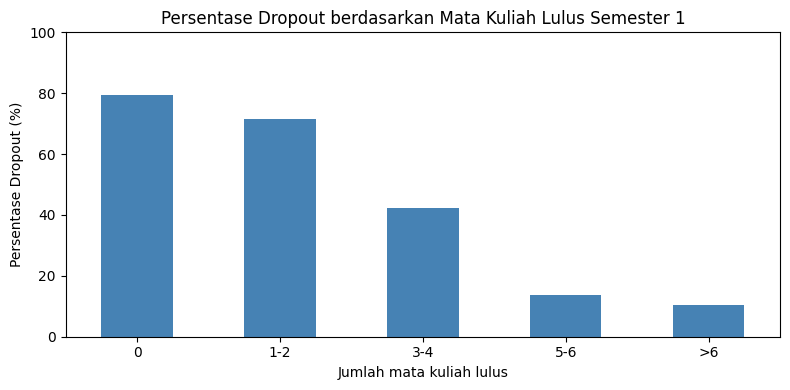

In [ ]:
kolom_lulus = "Curricular units 1st sem (approved)"

# Kelompokkan jumlah mata kuliah lulus
data_eda["Kelompok_Lulus"] = pd.cut(
    data_eda[kolom_lulus],
    bins=[-1, 0, 2, 4, 6, float("inf")],
    labels=["0", "1-2", "3-4", "5-6", ">6"]
)

# Persentase Dropout per kelompok
risiko_kelompok = (
    data_eda.groupby(
        "Kelompok_Lulus",
        observed=True
    )["Indikator_Dropout"]
    .agg(["mean", "count"])
)

risiko_kelompok["Persentase_Dropout"] = (
    risiko_kelompok["mean"] * 100
)

display(
    risiko_kelompok[
        ["count", "Persentase_Dropout"]
    ].round(2)
)

plt.figure(figsize=(8, 4))

risiko_kelompok["Persentase_Dropout"].plot(
    kind="bar",
    color="steelblue",
    rot=0
)

plt.title(
    "Persentase Dropout berdasarkan "
    "Mata Kuliah Lulus Semester 1"
)
plt.xlabel("Jumlah mata kuliah lulus")
plt.ylabel("Persentase Dropout (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

##Train-test split (80:20)

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Data latih:", len(X_train))
print("Data uji  :", len(X_test))
print("\nKelas data latih:")
print(y_train.value_counts())
print("\nKelas data uji:")
print(y_test.value_counts())

Data latih: 3539
Data uji  : 885

Kelas data latih:
Target
Graduate    1767
Dropout     1137
Enrolled     635
Name: count, dtype: int64

Kelas data uji:
Target
Graduate    442
Dropout     284
Enrolled    159
Name: count, dtype: int64


##Pemodelan

**Decision Tree** dan **Random Forest**

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

# Menyiapkan dua algoritma
percobaan = {
    "Decision Tree": (
        DecisionTreeClassifier(random_state=42),
        {
            "max_depth": [5, 8, 12],
            "min_samples_leaf": [2, 5, 10]
        }
    ),

    "Random Forest": (
        RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        ),
        {
            "max_depth": [8, None],
            "min_samples_leaf": [1, 3],
            "class_weight": [None, "balanced_subsample"]
        }
    )
}

# Tempat menyimpan hasil
model_terlatih = {}
hasil_cv = {}

# Cari parameter terbaik
for nama, (algoritma, parameter) in percobaan.items():

    print("\nSedang melatih:", nama)

    pencarian = GridSearchCV(
        estimator=algoritma,
        param_grid=parameter,
        cv=3,
        scoring="f1_macro",
        n_jobs=1
    )

    pencarian.fit(X_train, y_train)

    model_terlatih[nama] = pencarian.best_estimator_
    hasil_cv[nama] = pencarian.best_score_

    print("Parameter terbaik:", pencarian.best_params_)
    print(
        "Rata-rata Macro F1 validasi:",
        round(pencarian.best_score_, 4)
    )

# Pilih model berdasarkan Macro F1 validasi
nama_terbaik = max(hasil_cv, key=hasil_cv.get)
model_final = model_terlatih[nama_terbaik]

print("\nMODEL FINAL:", nama_terbaik)


Sedang melatih: Decision Tree
Parameter terbaik: {'max_depth': 12, 'min_samples_leaf': 10}
Rata-rata Macro F1 validasi: 0.6129

Sedang melatih: Random Forest
Parameter terbaik: {'class_weight': 'balanced_subsample', 'max_depth': 8, 'min_samples_leaf': 3}
Rata-rata Macro F1 validasi: 0.6638

MODEL FINAL: Random Forest


##Evaluasi pada test set

PERBANDINGAN MODEL PADA DATA TESTING


,Model,Accuracy (%),Macro F1,Precision Dropout (%),Recall Dropout (%),F1 Dropout (%)
0,Decision Tree,70.40,0.6219,71.96,68.66,70.27
1,Random Forest,69.49,0.6570,79.06,65.14,71.43



MODEL FINAL: Random Forest
              precision    recall  f1-score   support

     Dropout       0.79      0.65      0.71       284
    Enrolled       0.37      0.59      0.46       159
    Graduate       0.84      0.76      0.80       442

    accuracy                           0.69       885
   macro avg       0.67      0.67      0.66       885
weighted avg       0.74      0.69      0.71       885

Accuracy model final: 69.49 %


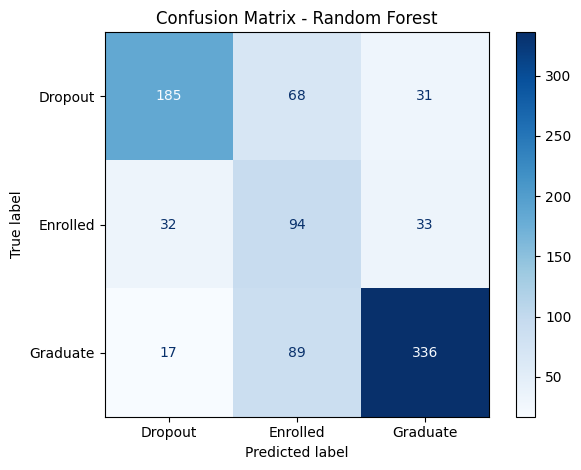

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

import pandas as pd
import matplotlib.pyplot as plt

hasil_evaluasi = []

# Menguji kedua model pada data testing
for nama, model in model_terlatih.items():

    prediksi = model.predict(X_test)

    hasil_evaluasi.append({
        "Model": nama,

        "Accuracy (%)": round(
            accuracy_score(y_test, prediksi) * 100, 2
        ),

        "Macro F1": round(
            f1_score(y_test, prediksi, average="macro"), 4
        ),

        "Precision Dropout (%)": round(
            precision_score(
                y_test, prediksi,
                labels=["Dropout"],
                average="macro",
                zero_division=0
            ) * 100, 2
        ),

        "Recall Dropout (%)": round(
            recall_score(
                y_test, prediksi,
                labels=["Dropout"],
                average="macro",
                zero_division=0
            ) * 100, 2
        ),

        "F1 Dropout (%)": round(
            f1_score(
                y_test, prediksi,
                labels=["Dropout"],
                average="macro",
                zero_division=0
            ) * 100, 2
        )
    })

# Menampilkan tabel perbandingan
hasil = pd.DataFrame(hasil_evaluasi)

print("PERBANDINGAN MODEL PADA DATA TESTING")
display(hasil)

# Evaluasi lebih rinci untuk model final
pred_final = model_final.predict(X_test)

print("\nMODEL FINAL:", nama_terbaik)

print(classification_report(
    y_test,
    pred_final,
    labels=["Dropout", "Enrolled", "Graduate"],
    zero_division=0
))

akurasi_final = accuracy_score(y_test, pred_final)

print(
    "Accuracy model final:",
    round(akurasi_final * 100, 2), "%"
)

# Confusion matrix model final
ConfusionMatrixDisplay.from_predictions(
    y_test,
    pred_final,
    labels=["Dropout", "Enrolled", "Graduate"],
    cmap="Blues"
)

plt.title("Confusion Matrix - " + nama_terbaik)
plt.tight_layout()
plt.show()

### Perbandingan Kedua Algoritma

,Model,Accuracy (%),Precision Dropout (%),Recall Dropout (%),F1 Dropout (%),Macro F1 (%)
0,Decision Tree,70.40,71.96,68.66,70.27,62.19
1,Random Forest,69.49,79.06,65.14,71.43,65.70


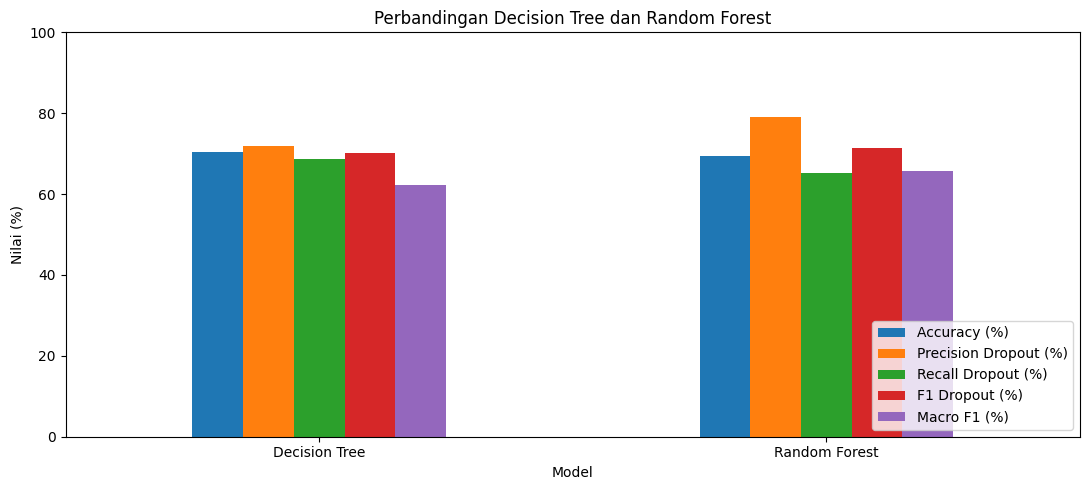

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

perbandingan = []

for nama, model in model_terlatih.items():

    prediksi = model.predict(X_test)

    perbandingan.append({
        "Model": nama,

        "Accuracy (%)": accuracy_score(
            y_test, prediksi
        ) * 100,

        "Precision Dropout (%)": precision_score(
            y_test, prediksi,
            labels=["Dropout"],
            average="macro",
            zero_division=0
        ) * 100,

        "Recall Dropout (%)": recall_score(
            y_test, prediksi,
            labels=["Dropout"],
            average="macro",
            zero_division=0
        ) * 100,

        "F1 Dropout (%)": f1_score(
            y_test, prediksi,
            labels=["Dropout"],
            average="macro",
            zero_division=0
        ) * 100,

        "Macro F1 (%)": f1_score(
            y_test, prediksi,
            average="macro"
        ) * 100
    })

hasil_lengkap = pd.DataFrame(perbandingan)

display(hasil_lengkap.round(2))

##Grafiknya
hasil_lengkap.set_index("Model").plot(
    kind="bar",
    figsize=(11, 5),
    rot=0
)

plt.title("Perbandingan Decision Tree dan Random Forest")
plt.ylabel("Nilai (%)")
plt.ylim(0, 100)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

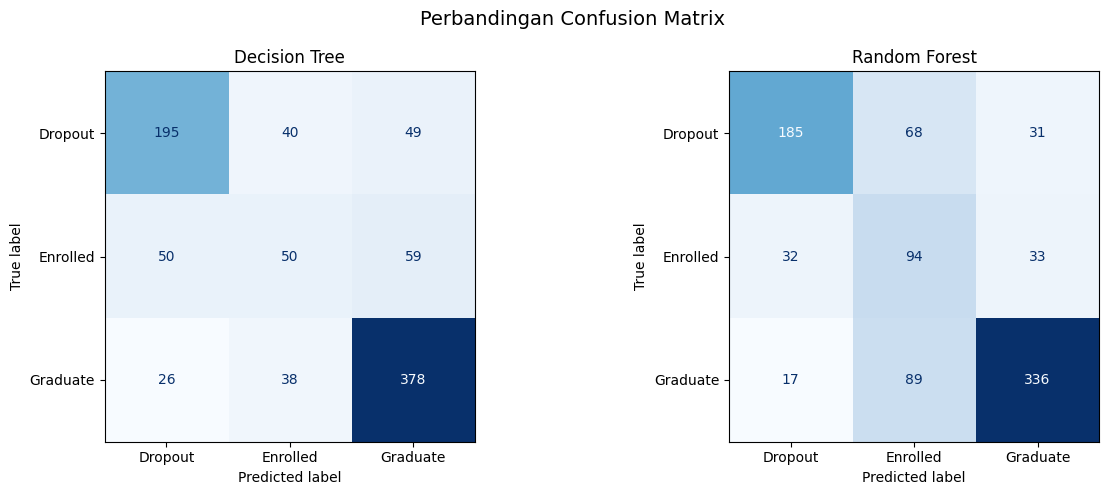

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 5)
)

for ax, (nama, model) in zip(
    axes,
    model_terlatih.items()
):

    prediksi = model.predict(X_test)

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        prediksi,
        labels=["Dropout", "Enrolled", "Graduate"],
        cmap="Blues",
        colorbar=False,
        ax=ax
    )

    ax.set_title(nama)

plt.suptitle(
    "Perbandingan Confusion Matrix",
    fontsize=14
)

plt.tight_layout()
plt.show()

##Interpretasi: fitur apa yang digunakan model?

`feature_importances_` menunjukkan kontribusi fitur dalam pemisahan pohon

Urutan fitur terpenting menurut Random Forest


,Importance
Curricular units 1st sem (approved),0.3132
Curricular units 1st sem (grade),0.2279
Tuition fees up to date,0.1283
Age at enrollment,0.1138
Admission grade,0.0936
Curricular units 1st sem (enrolled),0.0679
Scholarship holder,0.0552


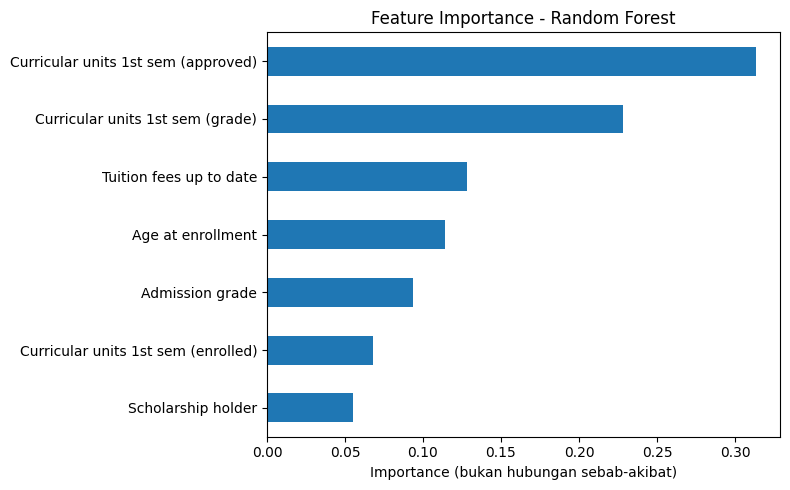

In [ ]:
penting = pd.Series(model_final.feature_importances_, index=fitur)
penting = penting.sort_values(ascending=False)

print("Urutan fitur terpenting menurut", nama_terbaik)
display(penting.round(4).to_frame("Importance"))
penting.sort_values().plot(kind="barh", figsize=(8, 5))
plt.title("Feature Importance - " + nama_terbaik)
plt.xlabel("Importance (bukan hubungan sebab-akibat)")
plt.tight_layout()
plt.show()

##Early Warning: 20 mahasiswa dengan skor Dropout tertinggi

`Precision@20` untuk ngukur berapa banyak anggota Top-20 yang memang berlabel Dropout. Hasil 20/20 bukan accuracy model 100%.

In [ ]:
kelas = list(model_final.classes_)
posisi_dropout = kelas.index("Dropout")

probabilitas = model_final.predict_proba(X_test)
risiko_dropout = probabilitas[:, posisi_dropout]

# Pilih peringkat probabilitas tertinggi.
indeks_top20 = np.argsort(risiko_dropout)[::-1][:20]

top20 = pd.DataFrame({
    "Peringkat": np.arange(1, len(indeks_top20) + 1),
    "Risiko Dropout (%)": (risiko_dropout[indeks_top20] * 100).round(2),
    "Status Sebenarnya": y_test.iloc[indeks_top20].values
})

display(top20)
benar_dropout = (top20["Status Sebenarnya"] == "Dropout").sum()
precision20 = benar_dropout / len(top20)
print("Jumlah Dropout aktual pada Top-20:", benar_dropout, "dari", len(top20))
print("Precision@20:", round(precision20 * 100, 2), "%")

,Peringkat,Risiko Dropout (%),Status Sebenarnya
0,1,99.34,Dropout
1,2,98.93,Dropout
2,3,98.91,Dropout
3,4,98.84,Dropout
4,5,98.57,Dropout
5,6,98.36,Dropout
6,7,98.24,Dropout
7,8,98.21,Dropout
8,9,98.14,Dropout
9,10,97.65,Dropout


Jumlah Dropout aktual pada Top-20: 20 dari 20
Precision@20: 100.0 %


##Prediksi mahasiswa baru

In [ ]:
import math

nama_input = [
    "Jumlah mata kuliah DIAMBIL semester 1",
    "Jumlah mata kuliah LULUS semester 1",
    "Nilai rata-rata semester 1",
    "Pembayaran biaya kuliah up-to-date? (0=Tidak, 1=Ya)",
    "Penerima beasiswa? (0=Tidak, 1=Ya)",
    "Nilai masuk perguruan tinggi",
    "Usia saat masuk kuliah"
]

# Indeks fitur yang harus berupa bilangan bulat, dan fitur kategori 0/1.
fitur_bulat = {0, 1, 3, 4, 6}
fitur_biner = {3, 4}

batas = {}
for i, kolom in enumerate(fitur):
    minimum = float(X[kolom].min())
    maksimum = float(X[kolom].max())
    if i in fitur_bulat:
        minimum, maksimum = int(minimum), int(maksimum)
    batas[kolom] = (minimum, maksimum)

# Nilai rata-rata semester 1 (indeks 2)
batas[fitur[2]] = (batas[fitur[2]][0], 20.0)

# Nilai masuk perguruan tinggi (indeks 5)
batas[fitur[5]] = (0.0, 200.0)

# Usia saat masuk kuliah (indeks 6)
batas[fitur[6]] = (1, float('inf'))

# Tampilkan batas riil sebelum meminta input
tabel_batas = pd.DataFrame([
    {
        "Fitur": nama_input[i],
        "Minimum": batas[kolom][0],
        "Maksimum": "Tidak ada batas" if batas[kolom][1] == float('inf') else batas[kolom][1],
        "Tipe input": "0 atau 1" if i in fitur_biner else (
            "Bilangan bulat" if i in fitur_bulat else "Angka/desimal"
        )
    }
    for i, kolom in enumerate(fitur)
])
print("RENTANG INPUT YANG DIPERBOLEHKAN:")
display(tabel_batas)


def minta_angka(nama, minimum, maksimum, bulat=False, opsi=None):
    """Terus bertanya sampai pengguna mengisi angka yang valid."""
    while True:
        if opsi is not None:
            petunjuk = "pilih 0 atau 1"
        else:
            maks_str = "tidak terbatas" if maksimum == float('inf') else maksimum
            petunjuk = f"{minimum} sampai {maks_str}"
            petunjuk += ", bilangan bulat" if bulat else ", boleh desimal"

        jawaban = input(f"{nama} [{petunjuk}]: ").strip()
        try:
            # Terima titik sebagai pemisah desimal; tolak kosong, NaN.
            angka = float(jawaban)
            if math.isnan(angka):
                raise ValueError
            if bulat and not angka.is_integer():
                print("  SALAH: harus bilangan bulat. Silakan ulangi.\n")
                continue
            nilai = int(angka) if bulat else angka
        except ValueError:
            print("  SALAH: masukkan angka yang valid, misalnya 8 atau 12.5. Ulangi.\n")
            continue

        if opsi is not None and nilai not in opsi:
            print("  SALAH: hanya boleh 0 atau 1. Silakan ulangi.\n")
        elif not minimum <= nilai <= maksimum:
            print(f"  SALAH: nilai harus dalam rentang {minimum} sampai {maks_str}. Ulangi.\n")
        else:
            return nilai


print("\n=== INPUT DATA MAHASISWA (akhir semester pertama) ===")
input_nilai = []
for i, kolom in enumerate(fitur):
    minimum, maksimum = batas[kolom]
    nilai = minta_angka(
        nama_input[i], minimum, maksimum,
        bulat=i in fitur_bulat,
        opsi=[0, 1] if i in fitur_biner else None
    )

    # Jika sudah mengisi jumlah yang diambil, jumlah lulus tidak boleh lebih tinggi.
    if i == 1:
        while nilai > input_nilai[0]:
            print(f"  SALAH: jumlah lulus ({nilai}) tidak boleh melebihi "
                  f"jumlah diambil ({input_nilai[0]}). Ulangi.\n")
            nilai = minta_angka(nama_input[i], minimum, maksimum, bulat=True)

    input_nilai.append(nilai)

# Urutan input harus sama dengan urutan fitur model.
input_baru = pd.DataFrame([input_nilai], columns=fitur)
print("\nDATA YANG AKAN DIPREDIKSI:")
display(input_baru)

status = model_final.predict(input_baru)[0]
proba_baru = model_final.predict_proba(input_baru)[0]
print("\n=== HASIL PREDIKSI AI ===")
print("Prediksi status:", status)
for kelas_i, peluang in zip(model_final.classes_, proba_baru):
    print(f"Skor {kelas_i}: {peluang * 100:.2f}%")

indeks_dropout = list(model_final.classes_).index("Dropout")
print(f"Skor risiko Dropout: {proba_baru[indeks_dropout] * 100:.2f}%")
print("Rekomendasi: verifikasi dan pendampingan oleh dosen wali jika diperlukan.")
print("Catatan: skor model belum terkalibrasi sebagai peluang dropout nyata :3")

RENTANG INPUT YANG DIPERBOLEHKAN:


,Fitur,Minimum,Maksimum,Tipe input
0,Jumlah mata kuliah DIAMBIL semester 1,0.0,26,Bilangan bulat
1,Jumlah mata kuliah LULUS semester 1,0.0,26,Bilangan bulat
2,Nilai rata-rata semester 1,0.0,20.0,Angka/desimal
3,"Pembayaran biaya kuliah up-to-date? (0=Tidak, ...",0.0,1,0 atau 1
4,"Penerima beasiswa? (0=Tidak, 1=Ya)",0.0,1,0 atau 1
5,Nilai masuk perguruan tinggi,0.0,200.0,Angka/desimal
6,Usia saat masuk kuliah,1.0,Tidak ada batas,Bilangan bulat



=== INPUT DATA MAHASISWA (akhir semester pertama) ===
